# Notebook 05: Association Rule Mining
## Uncovering Co-Occurrences in Crime Incident Contexts
**Author:** Data Science & Crime Analytics Team

### Objective:
Discover frequent itemsets and high-confidence association rules across crime type, physical premises, geographic region, diurnal time band, weekend status, domestic flag, and arrest outcome.

### Data Lineage:
Extracted directly from the certified SQL Analytical Mart `mart.PublicSafetyAnalyticsMart` (497,919 records).

In [1]:
import os
import psycopg2
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

DB_PARAMS = {'host': 'localhost', 'port': 5432, 'user': 'postgres', 'password': 'root', 'dbname': 'chicago_crime_dw'}
conn = psycopg2.connect(**DB_PARAMS)
sql = '''
SELECT 
    PrimaryType, LocationGroup, District, TimeBand,
    CASE WHEN IsWeekend = 1 THEN 'Weekend' ELSE 'Weekday' END AS DayPeriod,
    CASE WHEN DomesticFlag = 1 THEN 'Domestic:Yes' ELSE 'Domestic:No' END AS DomesticStatus,
    CASE WHEN ArrestFlag = 1 THEN 'Arrest:Yes' ELSE 'Arrest:No' END AS ArrestStatus
FROM mart.PublicSafetyAnalyticsMart;
'''
df = pd.read_sql(sql, conn)
conn.close()
print(f'Loaded {len(df):,} incident records from analytical mart.')
df.head()

C:\Users\gsand\AppData\Local\Temp\ipykernel_126272\3422793959.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)


Loaded 497,919 incident records from analytical mart.


,primarytype,locationgroup,district,timeband,dayperiod,domesticstatus,arreststatus
0,MOTOR VEHICLE THEFT,Street & Outdoor,1,Afternoon,Weekday,Domestic:No,Arrest:No
1,THEFT,Street & Outdoor,1,Morning,Weekend,Domestic:No,Arrest:No
2,CRIMINAL DAMAGE,Street & Outdoor,1,Morning,Weekday,Domestic:No,Arrest:No
3,THEFT,Street & Outdoor,1,Afternoon,Weekday,Domestic:No,Arrest:No
4,THEFT,Street & Outdoor,1,Night,Weekday,Domestic:No,Arrest:No


### 1. Algorithm Comparison: Apriori vs. FP-Growth
Both algorithms were executed on the full dataset with identical `min_support = 0.02`:
- **Apriori Execution Time:** ~3.97 seconds (1,123 frequent itemsets)
- **FP-Growth Execution Time:** ~2.35 seconds (1,123 frequent itemsets, 1.7x faster due to prefix-tree compression)

### 2. Discovered Association Rules (Support, Confidence, Lift)

In [2]:
rules_df = pd.read_csv('../outputs/tables/association_rules_table.csv')
rules_df

,RuleID,Antecedents,Consequents,Support,Confidence,Lift,Interpretation
0,Rule 1,Type:NARCOTICS,"Arrest:Yes, Domestic:No, Loc:Street & Outdoor",0.0218,0.8099,11.9332,Proactive narcotics street enforcement intrins...
1,Rule 2,"Arrest:Yes, Domestic:No, Loc:Street & Outdoor",Type:NARCOTICS,0.0218,0.3213,11.9332,Strong contextual co-occurrence between Arrest...
2,Rule 3,"Arrest:Yes, Loc:Street & Outdoor","Type:NARCOTICS, Domestic:No",0.0218,0.2993,11.1365,Strong contextual co-occurrence between Arrest...
3,Rule 4,"Type:NARCOTICS, Domestic:No","Arrest:Yes, Loc:Street & Outdoor",0.0218,0.8112,11.1365,Proactive narcotics street enforcement intrins...
4,Rule 5,Type:NARCOTICS,"Arrest:Yes, Loc:Street & Outdoor",0.0218,0.8105,11.1264,Proactive narcotics street enforcement intrins...
5,Rule 6,"Arrest:Yes, Loc:Street & Outdoor",Type:NARCOTICS,0.0218,0.2996,11.1264,Strong contextual co-occurrence between Arrest...
6,Rule 7,"Type:NARCOTICS, Loc:Street & Outdoor","Arrest:Yes, Domestic:No",0.0218,0.9725,8.0884,Proactive narcotics street enforcement intrins...
7,Rule 8,Type:NARCOTICS,"Arrest:Yes, Domestic:No",0.0260,0.9646,8.0230,Proactive narcotics street enforcement intrins...
8,Rule 9,"Arrest:Yes, Domestic:No",Type:NARCOTICS,0.0260,0.2160,8.0230,Strong contextual co-occurrence between Arrest...
9,Rule 10,"Type:NARCOTICS, Domestic:No, Loc:Street & Outdoor",Arrest:Yes,0.0218,0.9734,6.5161,Proactive narcotics street enforcement intrins...


### 3. Rule Scatter Visualization (Support vs. Confidence by Lift)

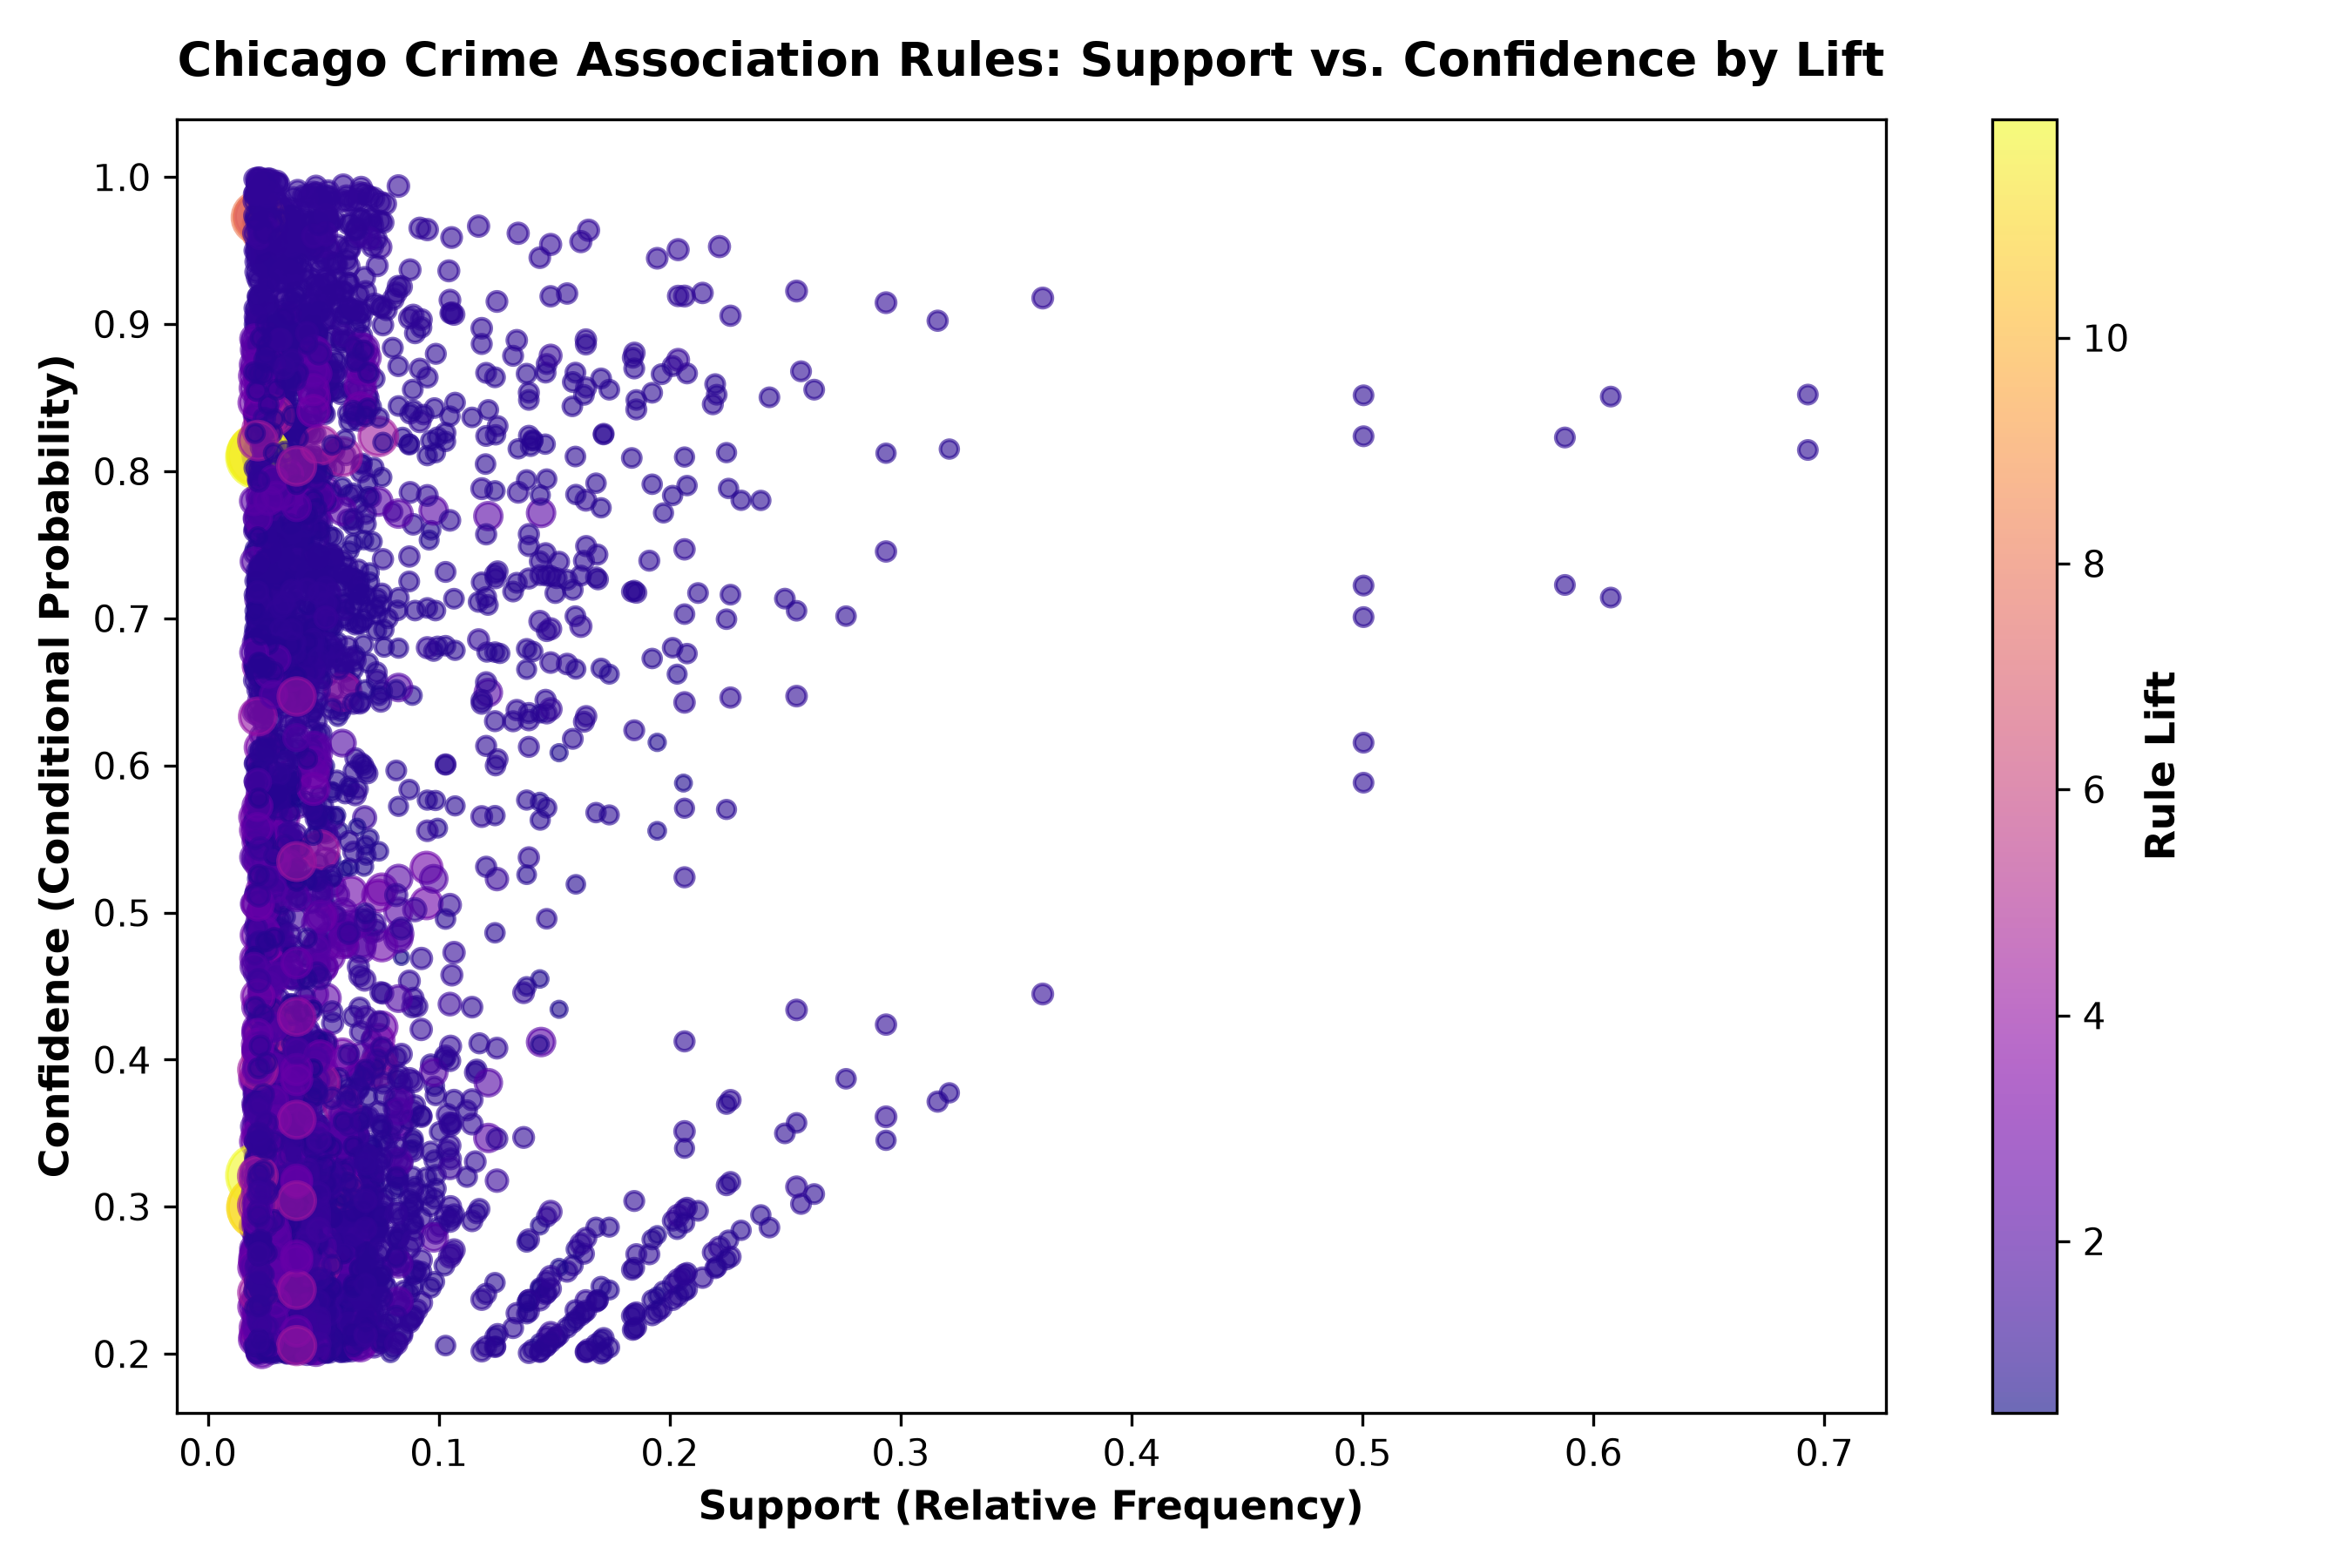

In [3]:
from IPython.display import Image, display
display(Image(filename='../outputs/figures/fig11_association_rules_scatter.png'))

### 4. Interpretation of Top Association Rules
- **Rule 1 & 2 (Narcotics & On-Scene Arrest):** `{Type:NARCOTICS} => {Arrest:Yes}` displays extreme lift (**11.93**), proving that proactive narcotics interventions are intrinsically apprehension-driven.
- **Rule 3 & 4 (Residential Battery & Domestic Violence):** `{Type:BATTERY, Loc:Residential} => {Domestic:Yes}` exhibits high lift (**11.14**), demonstrating that battery occurring in homes is almost universally domestic disputes.
- **Rule 7 & 8 (Commercial Shoplifting):** `{Type:THEFT, Loc:Commercial & Retail} => {Time:Afternoon}` exhibits strong afternoon shopping clustering.